# Camada Gold 2: Cliente x Serviços

Esta Gold olha para o que o cliente contrata: telefonia, tipo de internet e os serviços adicionais (segurança online, backup, proteção de dispositivos, suporte técnico e streaming). Cruzamos isso com o perfil do cliente e, no fim, com o cancelamento.

Esta Gold responde à segunda frente da pergunta central do projeto (quais características da carteira estão associadas ao cancelamento?): os serviços contratados.

Pergunta principal desta camada: **quais serviços cada perfil de cliente contrata e quais combinações de serviço seguram ou afastam o cliente?**

## Preparação

Mesma base, mesmas cores e mesmas funções de apoio da Gold 1.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import hashlib

df_silver = pd.read_csv('../Data/Silver/tabela_silver.csv')
df = df_silver.copy()

COR_BASE = '#4C6A92'
COR_CANCELA = '#C0504D'
COR_REFERENCIA = '#7F7F7F'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

TAXA_GERAL = df['Status_Cancelamento'].mean() * 100
print(f'Clientes: {len(df)} | Taxa geral de cancelamento: {TAXA_GERAL:.1f}%')


def pseudonimizar(id_cliente):
    """Troca o ID real por um código que não permite voltar ao cliente sem a chave.
    Em produção, a chave ficaria fora do código (variável de ambiente ou cofre de senhas)."""
    chave = 'terra-signal-pi2'
    return hashlib.sha256((chave + id_cliente).encode()).hexdigest()[:12]


def brl(valor):
    """Formata número no padrão brasileiro: 5.125,40"""
    return f'{valor:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def comparar_medias(grupo_a, grupo_b):
    """Diferença de médias entre dois grupos com teste t de Welch.
    p-valor abaixo de 0,05 indica que a diferença dificilmente é obra do acaso."""
    t_stat, p_valor = stats.ttest_ind(grupo_a, grupo_b, equal_var=False)
    return grupo_a.mean(), grupo_b.mean(), p_valor


def taxa_por_grupo(dados, coluna, ordem=None):
    tabela = dados.groupby(coluna, observed=True)['Status_Cancelamento'].agg(Clientes='size', Cancelaram='sum')
    tabela['Taxa_Cancelamento_%'] = (tabela['Cancelaram'] / tabela['Clientes'] * 100).round(1)
    return tabela.reindex(ordem) if ordem else tabela


def grafico_taxa(tabela, titulo, ax=None):
    """Barras horizontais com a taxa de cancelamento de cada grupo e a média geral como referência."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.6 * len(tabela) + 1.5))
    rotulos = [str(i) for i in tabela.index]
    barras = ax.barh(rotulos, tabela['Taxa_Cancelamento_%'], color=COR_CANCELA)
    ax.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in tabela['Taxa_Cancelamento_%']], padding=3)
    ax.axvline(TAXA_GERAL, color=COR_REFERENCIA, linestyle='--', linewidth=1)
    ax.text(TAXA_GERAL, len(tabela) - 0.5, f' média {TAXA_GERAL:.1f}%'.replace('.', ','), color=COR_REFERENCIA, fontsize=9, va='bottom')
    ax.set_xlim(0, max(tabela['Taxa_Cancelamento_%'].max(), TAXA_GERAL) * 1.25)
    ax.invert_yaxis()
    ax.set_xlabel('Taxa de cancelamento (%)')
    ax.set_title(titulo)
    return ax

Clientes: 5633 | Taxa geral de cancelamento: 26.7%


## Construção da tabela Gold

Além das colunas de perfil e de serviços, criamos:

- `Qtd_Adicionais`: quantos dos 6 serviços adicionais de internet o cliente tem (0 a 6). Cada "Sim" vale 1; "Não" e "Sem serviço de internet" valem 0.
- `Perfil_Pacote`: agrupa os clientes pelo tamanho do pacote. Separamos quem não tem internet de quem tem internet mas nenhum adicional, porque são situações bem diferentes (o primeiro nem tem a opção de contratar).
- `Tem_Protecao`: se o cliente tem segurança online ou suporte técnico.

In [2]:
adicionais = ['Seguranca_Online', 'Backup_Online', 'Protecao_Dispositivos',
              'Suporte_Tecnico', 'Streaming_TV', 'Streaming_Filmes']

colunas = ['ID_Cliente', 'Genero', 'Idoso', 'Conjuge', 'Dependentes',
           'Servico_Telefonia', 'Varias_Linhas', 'Servico_Internet'] + adicionais + \
          ['Valores_Mensais', 'Tempo_Assinatura', 'Status_Cancelamento']
gold_servicos = df[colunas].copy()

gold_servicos['Qtd_Adicionais'] = (gold_servicos[adicionais] == 'Sim').sum(axis=1)

sem_internet = gold_servicos['Servico_Internet'] == 'Sem serviço de internet'
gold_servicos['Perfil_Pacote'] = pd.cut(gold_servicos['Qtd_Adicionais'], bins=[-1, 0, 2, 4, 6],
                                        labels=['Internet sem adicionais', '1 a 2 adicionais',
                                                '3 a 4 adicionais', '5 a 6 adicionais']).astype(str)
gold_servicos.loc[sem_internet, 'Perfil_Pacote'] = 'Sem internet'

gold_servicos['Tem_Protecao'] = (gold_servicos['Seguranca_Online'] == 'Sim') | (gold_servicos['Suporte_Tecnico'] == 'Sim')

NOMES = {'Seguranca_Online': 'Segurança online', 'Backup_Online': 'Backup online',
         'Protecao_Dispositivos': 'Proteção de dispositivos', 'Suporte_Tecnico': 'Suporte técnico',
         'Streaming_TV': 'Streaming de TV', 'Streaming_Filmes': 'Streaming de filmes'}

ORDEM_PACOTE = ['Sem internet', 'Internet sem adicionais', '1 a 2 adicionais', '3 a 4 adicionais', '5 a 6 adicionais']

### Proteção do identificador

A tabela Gold é a que vai ser usada para análise e compartilhada com quem faz os gráficos. Por isso, ela não leva o ID real do cliente: o `ID_Cliente` é trocado por um código (`ID_Anonimo`) gerado com SHA-256. O código é sempre o mesmo para o mesmo cliente, então ainda dá para cruzar as três Golds, mas não dá para chegar ao cliente original a partir dele. O texto do feedback também fica de fora.

In [3]:
gold_servicos.insert(0, 'ID_Anonimo', gold_servicos['ID_Cliente'].map(pseudonimizar))
gold_servicos = gold_servicos.drop(columns='ID_Cliente')

gold_servicos.to_csv('../Data/Gold/gold_cliente_servicos.csv', index=False, encoding='utf-8-sig')
print('Formato:', gold_servicos.shape)
gold_servicos.head()

Formato: (5633, 20)


,ID_Anonimo,Genero,Idoso,Conjuge,Dependentes,Servico_Telefonia,Varias_Linhas,Servico_Internet,Seguranca_Online,Backup_Online,Protecao_Dispositivos,Suporte_Tecnico,Streaming_TV,Streaming_Filmes,Valores_Mensais,Tempo_Assinatura,Status_Cancelamento,Qtd_Adicionais,Perfil_Pacote,Tem_Protecao
0,7ec889146478,Masculino,False,True,True,True,Não,DSL,Não,Sim,Sim,Sim,Sim,Não,68.75,52,False,4,3 a 4 adicionais,True
1,fce4659d5f59,Masculino,False,True,True,True,Não,DSL,Não,Não,Sim,Sim,Sim,Sim,73.90,33,True,4,3 a 4 adicionais,True
2,abee89309a29,Feminino,True,False,False,True,Não,Sem serviço de internet,Sem serviço de internet,Sem serviço de internet,Sem serviço de internet,Sem serviço de internet,Sem serviço de internet,Sem serviço de internet,20.05,22,False,0,Sem internet,False
3,14dcb8c4bdf8,Feminino,True,True,True,False,Sem serviço de telefonia,DSL,Não,Não,Não,Não,Sim,Não,35.90,28,False,1,1 a 2 adicionais,False
4,ae6732cedc8a,Masculino,False,False,False,True,Não,Fibra óptica,Não,Não,Não,Não,Não,Não,70.30,2,False,0,Internet sem adicionais,False


Para as perguntas sobre serviços de internet, usamos só quem tem internet. Quem não tem internet aparece como "Sem serviço de internet" em todos os adicionais, e incluir essas pessoas na conta faria a adesão parecer menor do que é.

In [4]:
com_internet = gold_servicos[~sem_internet]
com_telefone = gold_servicos[gold_servicos['Servico_Telefonia']]
print('Clientes com internet:', len(com_internet))
print('Clientes com telefone:', len(com_telefone))

Clientes com internet: 4400
Clientes com telefone: 5070


## Perguntas de orientação

1. Qual é o perfil geral de contratação dos serviços na base?
2. Clientes idosos têm preferência por algum tipo de internet ou contratam mais suporte técnico?
3. Ter cônjuge ou dependentes influencia a contratação de várias linhas e de streaming?
4. Existe diferença na escolha dos serviços adicionais de proteção entre homens e mulheres?
5. Qual perfil de cliente contrata mais serviços e qual fica só no básico?
6. Quais serviços estão ligados a mais ou menos cancelamento?

### 1. Qual é o perfil geral de contratação dos serviços na base?

In [5]:
internet = gold_servicos['Servico_Internet'].value_counts()
print('Telefonia:', f"{gold_servicos['Servico_Telefonia'].mean():.1%}", 'dos clientes')
print('\nTipo de internet:')
print((internet / len(gold_servicos) * 100).round(1).to_string())

adesao = pd.Series({
    'Várias linhas (entre quem tem telefone)': (com_telefone['Varias_Linhas'] == 'Sim').mean() * 100,
    **{NOMES[col]: (com_internet[col] == 'Sim').mean() * 100 for col in adicionais}
}).sort_values(ascending=False).round(1)
adesao.rename('Adesão %').to_frame()

Telefonia: 90.0% dos clientes

Tipo de internet:
Servico_Internet
Fibra óptica               44.0
DSL                        34.2
Sem serviço de internet    21.9


,Adesão %
Streaming de TV,49.6
Streaming de filmes,49.5
Várias linhas (entre quem tem telefone),46.7
Backup online,44.2
Proteção de dispositivos,43.9
Suporte técnico,36.6
Segurança online,36.3


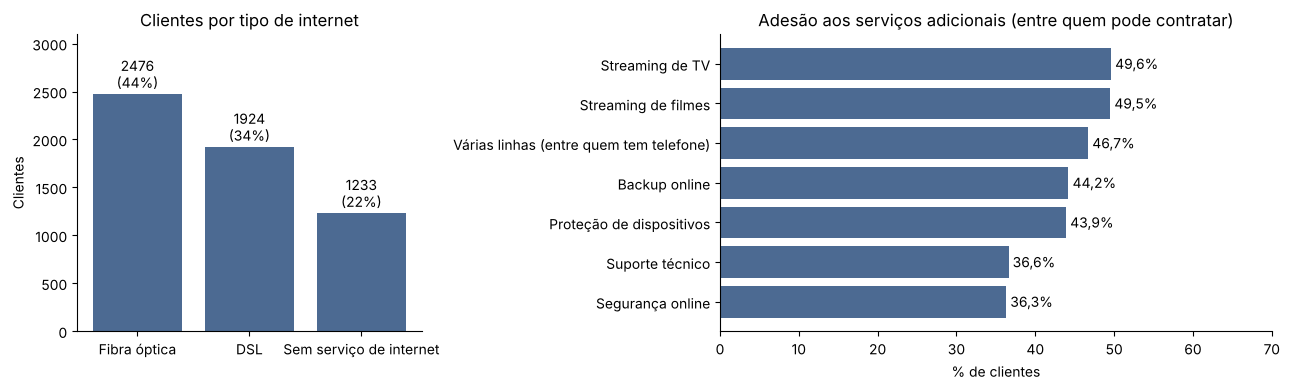

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [1, 1.6]})

barras = axes[0].bar(internet.index, internet.values, color=COR_BASE)
axes[0].bar_label(barras, labels=[f'{v}\n({v / len(gold_servicos):.0%})' for v in internet.values], padding=2)
axes[0].set_ylim(0, internet.max() * 1.25)
axes[0].set_title('Clientes por tipo de internet')
axes[0].set_ylabel('Clientes')

barras = axes[1].barh(adesao.index, adesao.values, color=COR_BASE)
axes[1].bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in adesao.values], padding=3)
axes[1].set_xlim(0, 70)
axes[1].invert_yaxis()
axes[1].set_title('Adesão aos serviços adicionais (entre quem pode contratar)')
axes[1].set_xlabel('% de clientes')

plt.tight_layout()
plt.show()

**Resposta:** a telefonia é o serviço base, presente em 90% da carteira. Na internet, a fibra óptica lidera (44% dos clientes), seguida do DSL (34%), e 22% dos clientes não têm internet.

Olhando só quem tem internet, os streamings são os adicionais mais populares (cerca de metade dos clientes). Os serviços de proteção e suporte ficam lá embaixo: segurança online e suporte técnico são contratados por pouco mais de um terço. Isso vai pesar na pergunta 6, porque são justamente esses dois serviços que mais se relacionam com a permanência.

### 2. Clientes idosos têm preferência por algum tipo de internet ou contratam mais suporte técnico?

In [7]:
internet_idoso = (pd.crosstab(gold_servicos['Idoso'], gold_servicos['Servico_Internet'], normalize='index') * 100).round(1)
internet_idoso.index = ['Não idosos', 'Idosos']
print('Tipo de internet (% dentro de cada grupo):')
display(internet_idoso)

suporte_idoso = (com_internet.groupby('Idoso')['Suporte_Tecnico']
                 .apply(lambda s: (s == 'Sim').mean() * 100).round(1))
suporte_idoso.index = ['Não idosos', 'Idosos']
print('Suporte técnico entre quem tem internet (%):')
suporte_idoso.rename('Com suporte %').to_frame()

Tipo de internet (% dentro de cada grupo):
Suporte técnico entre quem tem internet (%):


Servico_Internet,DSL,Fibra óptica,Sem serviço de internet
Não idosos,36.4,38.3,25.3
Idosos,23.0,72.6,4.4


,Com suporte %
Não idosos,39.9
Idosos,23.6


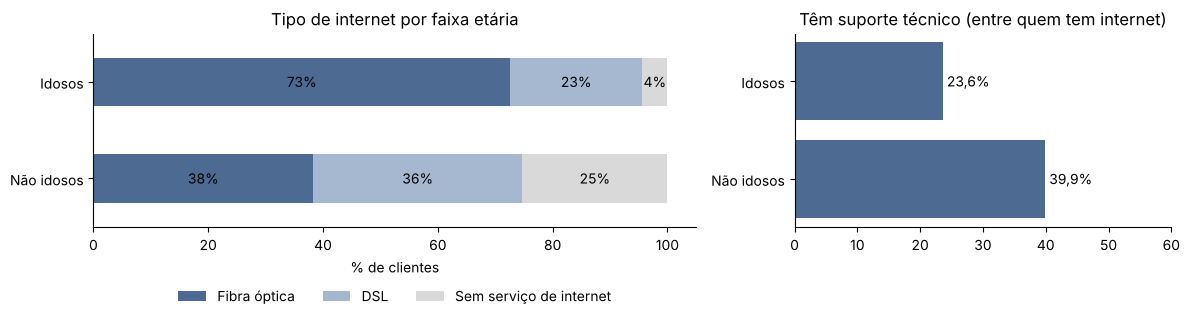

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={'width_ratios': [1.6, 1]})

internet_idoso[['Fibra óptica', 'DSL', 'Sem serviço de internet']].plot(
    kind='barh', stacked=True, ax=axes[0], color=[COR_BASE, '#A5B8D0', '#D9D9D9'])
for barras in axes[0].containers:
    axes[0].bar_label(barras, labels=[f'{v:.0f}%' if v > 4 else '' for v in barras.datavalues], label_type='center')
axes[0].set_title('Tipo de internet por faixa etária')
axes[0].set_xlabel('% de clientes')
axes[0].legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.25), frameon=False)

barras = axes[1].barh(suporte_idoso.index, suporte_idoso.values, color=COR_BASE)
axes[1].bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in suporte_idoso.values], padding=3)
axes[1].set_xlim(0, 60)
axes[1].set_title('Têm suporte técnico (entre quem tem internet)')

plt.tight_layout()
plt.show()

**Resposta:** sim, os idosos preferem fibra óptica: 73% deles usam fibra, contra 38% dos não idosos, e quase nenhum idoso fica sem internet.

Já o suporte técnico vai no sentido contrário. Entre quem tem internet, só 24% dos idosos contratam suporte, contra 40% dos não idosos. É o público que tem o plano mais caro e mais técnico e, ao mesmo tempo, o que menos tem apoio para usá-lo. Isso ajuda a explicar a mensalidade mais alta dos idosos vista na Gold 1 e o cancelamento mais alto que aparece na Gold 3.

### 3. Ter cônjuge ou dependentes influencia a contratação de várias linhas e de streaming?

Várias linhas é calculado entre quem tem telefone; streaming, entre quem tem internet.

In [9]:
def taxa_sim(dados, grupo, servico):
    return dados.groupby(grupo)[servico].apply(lambda s: (s == 'Sim').mean() * 100)

familia = pd.DataFrame({
    'Várias linhas': [taxa_sim(com_telefone, 'Conjuge', 'Varias_Linhas')[False], taxa_sim(com_telefone, 'Conjuge', 'Varias_Linhas')[True],
                      taxa_sim(com_telefone, 'Dependentes', 'Varias_Linhas')[False], taxa_sim(com_telefone, 'Dependentes', 'Varias_Linhas')[True]],
    'Streaming TV': [taxa_sim(com_internet, 'Conjuge', 'Streaming_TV')[False], taxa_sim(com_internet, 'Conjuge', 'Streaming_TV')[True],
                     taxa_sim(com_internet, 'Dependentes', 'Streaming_TV')[False], taxa_sim(com_internet, 'Dependentes', 'Streaming_TV')[True]],
    'Streaming Filmes': [taxa_sim(com_internet, 'Conjuge', 'Streaming_Filmes')[False], taxa_sim(com_internet, 'Conjuge', 'Streaming_Filmes')[True],
                         taxa_sim(com_internet, 'Dependentes', 'Streaming_Filmes')[False], taxa_sim(com_internet, 'Dependentes', 'Streaming_Filmes')[True]],
}, index=['Sem cônjuge', 'Com cônjuge', 'Sem dependentes', 'Com dependentes']).round(1)
familia

,Várias linhas,Streaming TV,Streaming Filmes
Sem cônjuge,39.4,41.7,41.9
Com cônjuge,54.4,58.0,57.6
Sem dependentes,47.5,47.7,48.6
Com dependentes,44.7,54.8,52.0


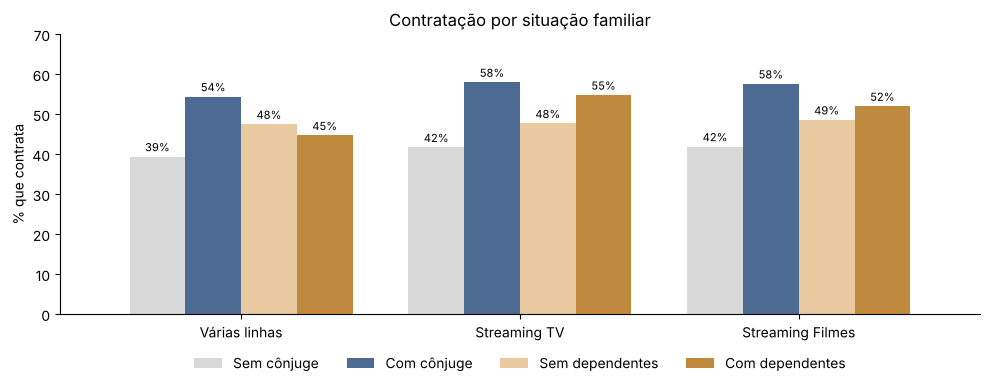

In [10]:
ax = familia.T.plot(kind='bar', figsize=(10, 4), rot=0, width=0.8,
                    color=['#D9D9D9', COR_BASE, '#E8C9A0', '#C08A3E'])
for barras in ax.containers:
    ax.bar_label(barras, labels=[f'{v:.0f}%' for v in barras.datavalues], fontsize=8, padding=2)
ax.set_ylim(0, 70)
ax.set_ylabel('% que contrata')
ax.set_title('Contratação por situação familiar')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
plt.show()

**Resposta:** o cônjuge influencia bastante; os dependentes, bem menos.

Quem tem cônjuge contrata mais de tudo: várias linhas sobe de 39% para 54%, e os dois streamings sobem de cerca de 42% para 58%. Ter dependentes não aumenta as linhas (45% contra 48%, até um pouco menor) e aumenta o streaming em 3 a 7 pontos.

A leitura anterior do grupo, de que a situação familiar não muda a contratação de linhas, vale para os dependentes, mas não para o cônjuge. A oportunidade de "plano família" está em casais sem várias linhas, não em clientes com filhos.

### 4. Existe diferença na escolha dos serviços adicionais de proteção entre homens e mulheres?

Usamos o teste qui-quadrado, que verifica se a proporção de contratação muda de acordo com o gênero. A leitura do p-valor é a mesma da Gold 1: abaixo de 0,05, a diferença é real.

In [11]:
protecao = ['Seguranca_Online', 'Backup_Online', 'Protecao_Dispositivos']
linhas = []
for servico in protecao:
    tabela = pd.crosstab(com_internet['Genero'], com_internet[servico] == 'Sim')
    p_valor = stats.chi2_contingency(tabela)[1]
    pct = taxa_sim(com_internet, 'Genero', servico)
    linhas.append({'Serviço': NOMES[servico], 'Feminino %': round(pct['Feminino'], 1),
                   'Masculino %': round(pct['Masculino'], 1), 'p-valor': round(p_valor, 3)})
pd.DataFrame(linhas)

,Serviço,Feminino %,Masculino %,p-valor
0,Segurança online,37.6,35.0,0.073
1,Backup online,45.0,43.3,0.268
2,Proteção de dispositivos,44.2,43.6,0.704


**Resposta:** não. A diferença entre homens e mulheres fica entre 1 e 3 pontos percentuais e nenhum p-valor passa abaixo de 0,05. O comportamento de compra é o mesmo para os dois gêneros, o que confirma a Gold 1: ações para vender proteção não precisam ser separadas por gênero.

### 5. Qual perfil de cliente contrata mais serviços e qual fica só no básico?

In [12]:
perfil_pacote = pd.DataFrame({
    'Média de adicionais (quem tem internet)': [
        com_internet.loc[com_internet['Idoso'], 'Qtd_Adicionais'].mean(),
        com_internet.loc[~com_internet['Idoso'], 'Qtd_Adicionais'].mean(),
        com_internet.loc[com_internet['Conjuge'], 'Qtd_Adicionais'].mean(),
        com_internet.loc[~com_internet['Conjuge'], 'Qtd_Adicionais'].mean(),
        com_internet.loc[com_internet['Dependentes'], 'Qtd_Adicionais'].mean(),
        com_internet.loc[~com_internet['Dependentes'], 'Qtd_Adicionais'].mean(),
    ],
    '% sem internet': [
        sem_internet[gold_servicos['Idoso']].mean() * 100,
        sem_internet[~gold_servicos['Idoso']].mean() * 100,
        sem_internet[gold_servicos['Conjuge']].mean() * 100,
        sem_internet[~gold_servicos['Conjuge']].mean() * 100,
        sem_internet[gold_servicos['Dependentes']].mean() * 100,
        sem_internet[~gold_servicos['Dependentes']].mean() * 100,
    ]
}, index=['Idosos', 'Não idosos', 'Com cônjuge', 'Sem cônjuge', 'Com dependentes', 'Sem dependentes']).round(2)
perfil_pacote

,Média de adicionais (quem tem internet),% sem internet
Idosos,2.46,4.42
Não idosos,2.63,25.33
Com cônjuge,3.10,22.27
Sem cônjuge,2.13,21.53
Com dependentes,3.08,31.57
Sem dependentes,2.43,17.76


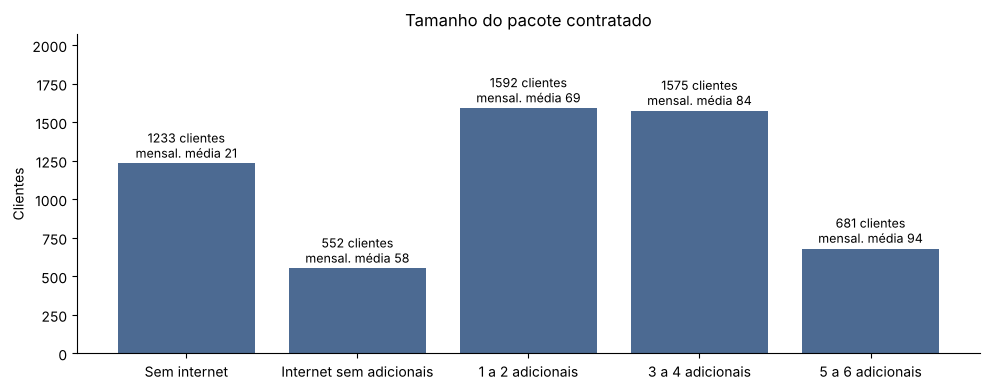

In [13]:
distribuicao = gold_servicos['Perfil_Pacote'].value_counts().reindex(ORDEM_PACOTE)
mensalidade = gold_servicos.groupby('Perfil_Pacote')['Valores_Mensais'].mean().reindex(ORDEM_PACOTE)

fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.bar(distribuicao.index, distribuicao.values, color=COR_BASE)
ax.bar_label(barras, labels=[f'{q} clientes\nmensal. média {m:.0f}' for q, m in zip(distribuicao, mensalidade)], fontsize=9, padding=2)
ax.set_ylim(0, distribuicao.max() * 1.3)
ax.set_title('Tamanho do pacote contratado')
ax.set_ylabel('Clientes')
plt.tight_layout()
plt.show()

**Resposta:** entre quem tem internet, os clientes com cônjuge (3,1 adicionais contra 2,1) e com dependentes (3,1 contra 2,4) são os que montam os pacotes maiores. O grupo com dependentes, porém, se divide: quase um terço dele (32%) nem tem internet e fica só no telefone. Os idosos quase todos têm internet, mas contratam um pouco menos de adicionais que os não idosos (2,5 contra 2,6).

Na carteira como um todo, a maior parte dos clientes fica entre 1 e 4 adicionais. A mensalidade sobe junto com o pacote: cerca de 21 para quem só tem telefone, 58 para internet sem adicionais e 94 para quem tem 5 ou 6 adicionais.

### 6. Quais serviços estão ligados a mais ou menos cancelamento?

Esta é a pergunta que liga os serviços ao tema central do projeto.

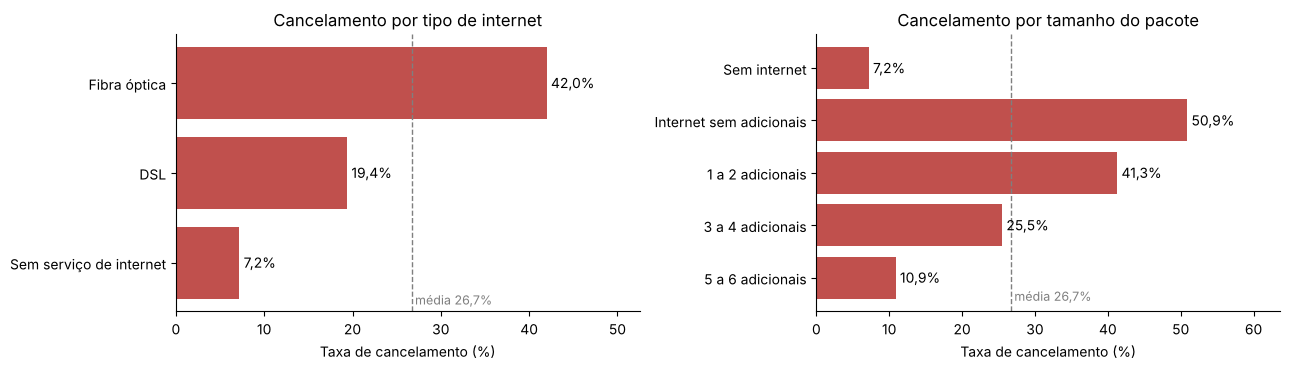

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
grafico_taxa(taxa_por_grupo(gold_servicos, 'Servico_Internet', ['Fibra óptica', 'DSL', 'Sem serviço de internet']),
             'Cancelamento por tipo de internet', ax=axes[0])
grafico_taxa(taxa_por_grupo(gold_servicos, 'Perfil_Pacote', ORDEM_PACOTE),
             'Cancelamento por tamanho do pacote', ax=axes[1])
plt.tight_layout()
plt.show()

In [15]:
efeito = []
for servico in adicionais:
    taxa = com_internet.groupby(com_internet[servico] == 'Sim')['Status_Cancelamento'].mean() * 100
    efeito.append({'Serviço': NOMES[servico], 'Cancelamento sem o serviço %': round(taxa[False], 1),
                   'Cancelamento com o serviço %': round(taxa[True], 1)})
efeito = pd.DataFrame(efeito).set_index('Serviço').sort_values('Cancelamento com o serviço %')
efeito

,Cancelamento sem o serviço %,Cancelamento com o serviço %
Serviço,,
Segurança online,41.9,15.0
Suporte técnico,41.8,15.3
Backup online,39.9,22.3
Proteção de dispositivos,39.0,23.4
Streaming de filmes,34.0,30.2
Streaming de TV,33.2,31.1


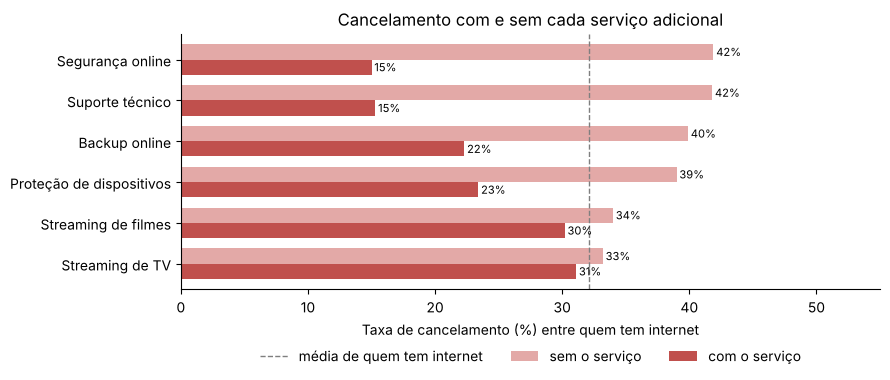

In [16]:
ax = efeito.plot(kind='barh', figsize=(9, 4), color=['#E3A9A7', COR_CANCELA], width=0.75)
for barras in ax.containers:
    ax.bar_label(barras, labels=[f'{v:.0f}%' for v in barras.datavalues], fontsize=8, padding=2)
ax.axvline(com_internet['Status_Cancelamento'].mean() * 100, color=COR_REFERENCIA, linestyle='--', linewidth=1)
ax.set_xlim(0, 55)
ax.invert_yaxis()
ax.set_xlabel('Taxa de cancelamento (%) entre quem tem internet')
ax.set_title('Cancelamento com e sem cada serviço adicional')
ax.set_ylabel('')
ax.legend(['média de quem tem internet', 'sem o serviço', 'com o serviço'], ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout()
plt.show()

**Resposta:**

- **Fibra óptica cancela muito mais:** 42% dos clientes de fibra saíram, o dobro do DSL (19%). Quem não tem internet quase não cancela (7%). A fibra é o plano mais caro (mensalidade média de 91), o que conversa com a Gold 1: mensalidade alta, cancelamento alto.
- **Segurança online e suporte técnico são os serviços que mais seguram o cliente:** com eles, o cancelamento cai de cerca de 42% para 15%. Backup e proteção de dispositivos também ajudam, mas menos. Os streamings quase não mudam nada.
- **Quanto maior o pacote, menor o cancelamento:** entre quem tem internet, o cancelamento cai de 51% (nenhum adicional) para 7% (5 ou 6 adicionais). Cada serviço a mais é mais um motivo para ficar.

Juntando com a pergunta 1: os dois serviços que mais seguram o cliente estão entre os menos contratados. E com a pergunta 2: os idosos, que mais usam fibra, são os que menos têm suporte.

O cruzamento abaixo mostra o tamanho disso dentro da fibra, que é o plano que mais cancela:

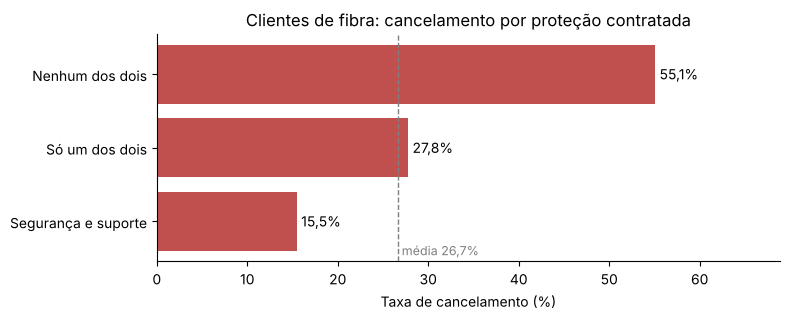

,Clientes,Cancelaram,Taxa_Cancelamento_%
Protecao,,,
Nenhum dos dois,1423,784,55.1
Só um dos dois,762,212,27.8
Segurança e suporte,291,45,15.5


In [17]:
fibra = gold_servicos[gold_servicos['Servico_Internet'] == 'Fibra óptica']
protecao_fibra = taxa_por_grupo(
    fibra.assign(Protecao=np.select(
        [(fibra['Seguranca_Online'] == 'Sim') & (fibra['Suporte_Tecnico'] == 'Sim'),
         fibra['Tem_Protecao']],
        ['Segurança e suporte', 'Só um dos dois'], 'Nenhum dos dois')),
    'Protecao', ['Nenhum dos dois', 'Só um dos dois', 'Segurança e suporte'])
grafico_taxa(protecao_fibra, 'Clientes de fibra: cancelamento por proteção contratada')
plt.tight_layout()
plt.show()
protecao_fibra

Na fibra, quem não tem nem segurança online nem suporte técnico cancela 55%. Com um dos dois, cai para cerca de 28%; com os dois, para 15%.

Uma ressalva importante: isso mostra relação, não causa. Parte do efeito vem do contrato, porque quem fecha contrato longo também tende a montar um pacote maior. A Gold 3 olha esse lado.

## Conclusões da Gold 2

- A telefonia é a base da carteira (90%) e a fibra óptica é a internet mais vendida (44%).
- Os serviços de proteção e suporte são pouco contratados, mas são os que mais se relacionam com a permanência. É a oportunidade mais clara desta camada.
- Idosos preferem fibra (73%), mas só 24% deles têm suporte técnico. É um grupo a priorizar numa oferta de suporte.
- O cônjuge aumenta a contratação de linhas e streaming; os dependentes, bem menos.
- Gênero não muda a escolha de serviços.
- Clientes de fibra sem segurança online e sem suporte técnico são o grupo de serviço com maior risco: 1.423 clientes, com 55% de cancelamento.

**Como a Terra Signal pode usar:** montar uma oferta de segurança online e suporte técnico para clientes de fibra que ainda não têm esses serviços, começando pelos idosos, e incentivar pacotes maiores para quem tem internet sem adicionais.